# Exploración completa y preparación — Lending Club

**Pregunta predictiva del proyecto:** Dado un préstamo que Lending Club acaba de aprobar, y usando únicamente la información disponible el día del desembolso, ¿qué probabilidad hay de que termine declarado incobrable (`Charged Off`) en lugar de pagarse por completo (`Fully Paid`)?

Este notebook carga las 97 columnas seleccionadas con tipos compactos, revisa los faltantes en la primera ventana de entrenamiento (préstamos elegibles hasta 2012) y conserva las 26 predictoras con menos del 10% de faltantes en esa ventana. Compara las distribuciones antes y después de una imputación **solo descriptiva**.

## 1. Configuración inicial del entorno

Localizamos la raíz desde el directorio actual o `PROYECTO_ML_RAIZ` y añadimos una sola vez su ruta a `sys.path`. La misma celda funciona desde la raíz y desde `notebooks/`. Los módulos compartidos mantienen el muestreo y los cortes; el módulo del modelo conserva su preparación específica.

In [17]:
from pathlib import Path
import sys, os
candidatos_raiz = [Path(os.environ.get("PROYECTO_ML_RAIZ", Path.cwd())).resolve()]
if "__file__" in globals():
    candidatos_raiz.append(Path(__file__).resolve().parent)
raiz_encontrada = next((p for base in candidatos_raiz for p in [base, *base.parents]
                        if (p / "src/config.py").is_file()), None)
if raiz_encontrada is None:
    raise FileNotFoundError("Abra Jupyter dentro del proyecto o defina PROYECTO_ML_RAIZ.")
if str(raiz_encontrada) not in sys.path:
    sys.path.insert(0, str(raiz_encontrada))
from src.rutas import raiz_proyecto
RAIZ = raiz_proyecto(raiz_encontrada)
carpeta = RAIZ


### Control de ejecución: consulta o reproducción

`REPRODUCIR = False` permite consultar las tablas, configuraciones y figuras históricas. En este modo no se carga el CSV original ni se entrenan modelos, buscan hiperparámetros o recalibran probabilidades. Si falta algún resultado histórico, el notebook indica qué archivo o sección no está disponible; no ejecuta un entrenamiento para reemplazarlo.

Para repetir el experimento, cambia a `REPRODUCIR = True` y ejecuta todas las celdas en orden después de reiniciar el kernel. El notebook cargará el CSV y repetirá el experimento con los periodos, las semillas y la preparación definidos.

`RUTA_DATOS` indica **dónde está el archivo CSV** que se usará para reproducir el experimento. Si el archivo está en una ubicación habitual del proyecto, deja `RUTA_DATOS = None` para que el notebook lo localice. Si está en otra ubicación, escribe la ruta completa al archivo, por ejemplo:

```python
RUTA_DATOS = r"C:\datos\accepted_loans.csv"
```

In [18]:
REPRODUCIR = False
RUTA_DATOS = None

In [19]:
from src.reproduccion_notebooks import SesionNotebook, mostrar_resultados_guardados
import json
import pandas as pd
from IPython.display import Image, display
sesion = SesionNotebook(RAIZ, '04_exploracion', REPRODUCIR, RUTA_DATOS)
BASE_REPRODUCCIONES = sesion.base
ORIGEN = RAIZ / "outputs" / 'exploracion_completa'
SALIDA = sesion.salida if REPRODUCIR else ORIGEN
def exigir_reproduccion():
    if not REPRODUCIR:
        raise RuntimeError("Esta operación requiere REPRODUCIR = True.")
    if not sesion.reproducir:
        raise RuntimeError("Reinicia el kernel y ejecuta desde el principio para reproducir.")
    sesion.exigir()
    if SALIDA != sesion.salida:
        raise RuntimeError("Reinicia el kernel: no cambies el destino a una carpeta histórica.")
PARES_VERIFICACION = [
    (RAIZ / "outputs" / 'exploracion_completa/faltantes_97_hasta_2012.csv', SALIDA / 'faltantes_97_hasta_2012.csv'),
    (RAIZ / "outputs" / 'comparacion_carga/bloques_1.json', SALIDA / 'comparacion_carga/bloques_1.json'),
    (RAIZ / "outputs" / 'comparacion_carga/bloques_2.json', SALIDA / 'comparacion_carga/bloques_2.json'),
    (RAIZ / "outputs" / 'comparacion_carga/bloques_3.json', SALIDA / 'comparacion_carga/bloques_3.json'),
    (RAIZ / "outputs" / 'comparacion_carga/directa_1.json', SALIDA / 'comparacion_carga/directa_1.json'),
    (RAIZ / "outputs" / 'comparacion_carga/directa_2.json', SALIDA / 'comparacion_carga/directa_2.json'),
    (RAIZ / "outputs" / 'comparacion_carga/directa_3.json', SALIDA / 'comparacion_carga/directa_3.json'),
    (RAIZ / "outputs" / 'benchmark_memoria/bloques_1.json', SALIDA / 'benchmark_memoria/bloques_1.json'),
    (RAIZ / "outputs" / 'benchmark_memoria/bloques_2.json', SALIDA / 'benchmark_memoria/bloques_2.json'),
    (RAIZ / "outputs" / 'benchmark_memoria/directa_1.json', SALIDA / 'benchmark_memoria/directa_1.json'),
    (RAIZ / "outputs" / 'benchmark_memoria/directa_2.json', SALIDA / 'benchmark_memoria/directa_2.json'),
    (RAIZ / "outputs" / 'exploracion_completa/cobertura_predictoras_hasta_2012_umbral_10.csv', SALIDA / 'cobertura_predictoras_hasta_2012_umbral_10.csv'),
    (RAIZ / "outputs" / 'exploracion_completa/correlacion_antes.csv', SALIDA / 'correlacion_antes.csv'),
    (RAIZ / "outputs" / 'exploracion_completa/correlacion_despues.csv', SALIDA / 'correlacion_despues.csv'),
    (RAIZ / "outputs" / 'exploracion_completa/comparacion_iqr.csv', SALIDA / 'comparacion_iqr.csv'),
]
sesion.requerir([a for a, _ in PARES_VERIFICACION if a.is_file()])
INDICE_CONSULTA = RAIZ / "outputs/exploracion_completa/consulta.json"
sesion.requerir([INDICE_CONSULTA])

Modo reproducción: se ejecutará el procedimiento original al correr las celdas.
Salidas independientes: C:\Users\josue\Proyecto-ML-Grupo8\outputs\reproducciones\04_exploracion_20261120_161625_800291_6b380733


## 2. Preparar la lectura y los nombres para presentar

In [20]:
if REPRODUCIR:
    exigir_reproduccion()
    import time
    import gc
    import numpy as np
    import matplotlib.pyplot as plt

    carpeta = raiz_proyecto()
    if carpeta.name == "notebooks":
        carpeta = carpeta.parent
    if str(carpeta) not in sys.path:
        sys.path.insert(0, str(carpeta))

    from src.config import localizar_datos, ANIO_CORTE_VALIDACION, ANIO_CORTE_PRUEBA, UMBRAL_FALTANTES_FINAL as UMBRAL_FALTANTES
    from src.features import seleccionar_predictoras, preparar_matriz

    archivo = localizar_datos(RUTA_DATOS)
    print("Archivo:", archivo)
    print(f"Tamaño en disco: {archivo.stat().st_size / 1024**3:.2f} GiB")

    tipos_auditados = {'acc_now_delinq': 'Int8', 'acc_open_past_24mths': 'Int8', 'addr_state': 'category', 'all_util': 'Int16', 'annual_inc': 'float64', 'annual_inc_joint': 'float64', 'application_type': 'category', 'avg_cur_bal': 'Int32', 'bc_open_to_buy': 'Int32', 'bc_util': 'float64', 'chargeoff_within_12_mths': 'Int8', 'collection_recovery_fee': 'float64', 'collections_12_mths_ex_med': 'Int8', 'debt_settlement_flag': 'category', 'debt_settlement_flag_date': 'category', 'deferral_term': 'Int8', 'delinq_2yrs': 'Int8', 'delinq_amnt': 'Int32', 'desc': 'string', 'disbursement_method': 'category', 'dti': 'float64', 'dti_joint': 'float64', 'earliest_cr_line': 'string', 'emp_length': 'category', 'emp_title': 'string', 'fico_range_high': 'Int16', 'fico_range_low': 'Int16', 'funded_amnt': 'Int32', 'funded_amnt_inv': 'float64', 'grade': 'category', 'hardship_amount': 'float64', 'hardship_dpd': 'Int8', 'hardship_end_date': 'category', 'hardship_flag': 'category', 'hardship_last_payment_amount': 'float64', 'hardship_length': 'Int8', 'hardship_loan_status': 'category', 'hardship_payoff_balance_amount': 'float64', 'hardship_reason': 'category', 'hardship_start_date': 'category', 'hardship_status': 'category', 'hardship_type': 'category', 'home_ownership': 'category', 'id': 'string', 'il_util': 'Int16', 'initial_list_status': 'category', 'inq_fi': 'Int8', 'inq_last_12m': 'Int8', 'inq_last_6mths': 'Int8', 'installment': 'float64', 'int_rate': 'float64', 'issue_d': 'string', 'last_credit_pull_d': 'category', 'last_fico_range_high': 'Int16', 'last_fico_range_low': 'Int16', 'last_pymnt_amnt': 'float64', 'last_pymnt_d': 'category', 'loan_amnt': 'Int32', 'loan_status': 'category', 'max_bal_bc': 'Int32', 'member_id': 'string', 'mo_sin_old_il_acct': 'Int16', 'mo_sin_old_rev_tl_op': 'Int16', 'mo_sin_rcnt_rev_tl_op': 'Int16', 'mo_sin_rcnt_tl': 'Int16', 'mort_acc': 'Int8', 'mths_since_last_delinq': 'Int16', 'mths_since_last_major_derog': 'Int16', 'mths_since_last_record': 'Int16', 'mths_since_rcnt_il': 'Int16', 'mths_since_recent_bc': 'Int16', 'mths_since_recent_bc_dlq': 'Int16', 'mths_since_recent_inq': 'Int8', 'mths_since_recent_revol_delinq': 'Int16', 'next_pymnt_d': 'category', 'num_accts_ever_120_pd': 'Int8', 'num_actv_bc_tl': 'Int8', 'num_actv_rev_tl': 'Int8', 'num_bc_sats': 'Int8', 'num_bc_tl': 'Int8', 'num_il_tl': 'Int16', 'num_op_rev_tl': 'Int8', 'num_rev_accts': 'Int16', 'num_rev_tl_bal_gt_0': 'Int8', 'num_sats': 'Int8', 'num_tl_120dpd_2m': 'Int8', 'num_tl_30dpd': 'Int8', 'num_tl_90g_dpd_24m': 'Int8', 'num_tl_op_past_12m': 'Int8', 'open_acc': 'Int8', 'open_acc_6m': 'Int8', 'open_act_il': 'Int8', 'open_il_12m': 'Int8', 'open_il_24m': 'Int8', 'open_rv_12m': 'Int8', 'open_rv_24m': 'Int8', 'orig_projected_additional_accrued_interest': 'float64', 'out_prncp': 'float64', 'out_prncp_inv': 'float64', 'payment_plan_start_date': 'category', 'pct_tl_nvr_dlq': 'float64', 'percent_bc_gt_75': 'float64', 'policy_code': 'category', 'pub_rec': 'Int8', 'pub_rec_bankruptcies': 'Int8', 'purpose': 'category', 'pymnt_plan': 'category', 'recoveries': 'float64', 'revol_bal': 'Int32', 'revol_bal_joint': 'Int32', 'revol_util': 'float64', 'sec_app_chargeoff_within_12_mths': 'Int8', 'sec_app_collections_12_mths_ex_med': 'Int8', 'sec_app_earliest_cr_line': 'string', 'sec_app_fico_range_high': 'Int16', 'sec_app_fico_range_low': 'Int16', 'sec_app_inq_last_6mths': 'Int8', 'sec_app_mort_acc': 'Int8', 'sec_app_mths_since_last_major_derog': 'Int16', 'sec_app_num_rev_accts': 'Int8', 'sec_app_open_acc': 'Int8', 'sec_app_open_act_il': 'Int8', 'sec_app_revol_util': 'float64', 'settlement_amount': 'float64', 'settlement_date': 'category', 'settlement_percentage': 'float64', 'settlement_status': 'category', 'settlement_term': 'Int16', 'sub_grade': 'category', 'tax_liens': 'Int8', 'term': 'category', 'title': 'string', 'tot_coll_amt': 'Int32', 'tot_cur_bal': 'Int32', 'tot_hi_cred_lim': 'Int32', 'total_acc': 'Int16', 'total_bal_ex_mort': 'Int32', 'total_bal_il': 'Int32', 'total_bc_limit': 'Int32', 'total_cu_tl': 'Int8', 'total_il_high_credit_limit': 'Int32', 'total_pymnt': 'float64', 'total_pymnt_inv': 'float64', 'total_rec_int': 'float64', 'total_rec_late_fee': 'float64', 'total_rec_prncp': 'float64', 'total_rev_hi_lim': 'Int32', 'url': 'string', 'verification_status': 'category', 'verification_status_joint': 'category', 'zip_code': 'category'}

    nombres_variables = {'acc_now_delinq': 'cuentas_en_mora_actual', 'acc_open_past_24mths': 'cuentas_abiertas_ultimos_24m', 'annual_inc': 'ingreso_anual', 'avg_cur_bal': 'saldo_promedio_cuentas', 'bc_open_to_buy': 'credito_disponible_tarjetas', 'bc_util': 'utilizacion_tarjetas_pct', 'chargeoff_within_12_mths': 'cuentas_castigadas_12m', 'collections_12_mths_ex_med': 'cobranzas_no_medicas_12m', 'delinq_2yrs': 'moras_ultimos_2_anios', 'delinq_amnt': 'monto_en_mora_actual', 'dti': 'ratio_deuda_ingreso', 'fico_range_high': 'fico_limite_superior', 'fico_range_low': 'fico_limite_inferior', 'inq_last_6mths': 'consultas_credito_6m', 'loan_amnt': 'monto_prestamo', 'mo_sin_old_il_acct': 'meses_desde_cuenta_plazos_mas_antigua', 'mo_sin_old_rev_tl_op': 'meses_desde_revolvente_mas_antigua', 'mo_sin_rcnt_rev_tl_op': 'meses_desde_revolvente_mas_reciente', 'mo_sin_rcnt_tl': 'meses_desde_cuenta_mas_reciente', 'mort_acc': 'cuentas_hipotecarias', 'mths_since_last_delinq': 'meses_desde_ultima_mora', 'mths_since_last_major_derog': 'meses_desde_ultima_mora_grave', 'mths_since_last_record': 'meses_desde_ultimo_registro_publico', 'mths_since_recent_bc': 'meses_desde_tarjeta_mas_reciente', 'mths_since_recent_bc_dlq': 'meses_desde_ultima_mora_tarjeta', 'mths_since_recent_inq': 'meses_desde_ultima_consulta_credito', 'mths_since_recent_revol_delinq': 'meses_desde_ultima_mora_revolvente', 'num_accts_ever_120_pd': 'cuentas_con_mora_120_dias', 'num_actv_bc_tl': 'tarjetas_bancarias_activas', 'num_actv_rev_tl': 'cuentas_revolventes_activas', 'num_bc_sats': 'tarjetas_bancarias_al_dia', 'num_bc_tl': 'total_cuentas_tarjeta', 'num_il_tl': 'total_cuentas_plazos', 'num_op_rev_tl': 'cuentas_revolventes_abiertas', 'num_rev_accts': 'total_cuentas_revolventes', 'num_rev_tl_bal_gt_0': 'revolventes_con_saldo', 'num_sats': 'cuentas_satisfactorias', 'num_tl_120dpd_2m': 'cuentas_mora_120_dias_ultimos_2m', 'num_tl_30dpd': 'cuentas_mora_30_dias_actual', 'num_tl_90g_dpd_24m': 'cuentas_mora_90_mas_dias_24m', 'num_tl_op_past_12m': 'cuentas_abiertas_12m', 'open_acc': 'lineas_credito_abiertas', 'pct_tl_nvr_dlq': 'pct_cuentas_sin_mora', 'percent_bc_gt_75': 'pct_tarjetas_utilizacion_mayor_75', 'pub_rec': 'registros_publicos_adversos', 'pub_rec_bankruptcies': 'quiebras_registradas', 'revol_bal': 'saldo_credito_revolvente', 'revol_util': 'utilizacion_credito_revolvente_pct', 'tax_liens': 'gravamenes_fiscales', 'term': 'plazo_meses', 'tot_coll_amt': 'monto_total_cobranzas', 'tot_cur_bal': 'saldo_total_actual', 'tot_hi_cred_lim': 'limite_credito_total', 'total_acc': 'total_lineas_credito', 'total_bal_ex_mort': 'saldo_total_sin_hipoteca', 'total_bc_limit': 'limite_total_tarjetas', 'total_il_high_credit_limit': 'limite_total_creditos_plazos', 'total_rev_hi_lim': 'limite_total_credito_revolvente', 'emp_length': 'antiguedad_laboral', 'home_ownership': 'tenencia_vivienda', 'verification_status': 'verificacion_ingresos', 'purpose': 'proposito_prestamo', 'addr_state': 'estado_residencia', 'application_type': 'tipo_solicitud', 'earliest_cr_line': 'fecha_primera_linea_credito', 'issue_d': 'fecha_otorgamiento', 'loan_status': 'estado_prestamo', 'verification_status_joint': 'verificacion_ingresos_conjunta', 'all_util': 'utilizacion_global_pct', 'annual_inc_joint': 'ingreso_anual_conjunto', 'dti_joint': 'ratio_deuda_ingreso_conjunto', 'open_acc_6m': 'creditos_abiertos_6m', 'open_act_il': 'creditos_plazo_activos', 'open_il_12m': 'creditos_plazo_abiertos_12m', 'open_il_24m': 'creditos_plazo_abiertos_24m', 'mths_since_rcnt_il': 'meses_desde_credito_plazo_reciente', 'total_bal_il': 'saldo_total_creditos_plazo', 'il_util': 'utilizacion_creditos_plazo_pct', 'open_rv_12m': 'creditos_revolventes_abiertos_12m', 'open_rv_24m': 'creditos_revolventes_abiertos_24m', 'max_bal_bc': 'saldo_maximo_tarjetas', 'inq_fi': 'consultas_financieras', 'total_cu_tl': 'cuentas_credito_uniones', 'inq_last_12m': 'consultas_credito_12m', 'revol_bal_joint': 'saldo_revolvente_conjunto', 'sec_app_fico_range_low': 'fico_inferior_solicitante_secundario', 'sec_app_fico_range_high': 'fico_superior_solicitante_secundario', 'sec_app_earliest_cr_line': 'fecha_credito_mas_antiguo_secundario', 'sec_app_inq_last_6mths': 'consultas_credito_6m_secundario', 'sec_app_mort_acc': 'cuentas_hipotecarias_secundario', 'sec_app_open_acc': 'lineas_credito_abiertas_secundario', 'sec_app_revol_util': 'utilizacion_revolvente_secundario_pct', 'sec_app_open_act_il': 'creditos_plazo_activos_secundario', 'sec_app_num_rev_accts': 'cuentas_revolventes_secundario', 'sec_app_chargeoff_within_12_mths': 'castigos_12m_secundario', 'sec_app_collections_12_mths_ex_med': 'cobranzas_12m_secundario', 'sec_app_mths_since_last_major_derog': 'meses_desde_mora_grave_secundario', 'meses_desde_earliest_cr_line': 'antiguedad_historial_crediticio_meses', 'meses_desde_sec_app_earliest_cr_line': 'antiguedad_historial_secundario_meses', 'default': 'incumplimiento'}

    def mostrar_nombres_espanol(tabla):
        vista = tabla.copy()
        vista.index = [nombres_variables.get(str(nombre), str(nombre)) for nombre in vista.index]
        vista.columns = [nombres_variables.get(str(nombre), str(nombre)) for nombre in vista.columns]
        return vista
else:
    mostrar_resultados_guardados(RAIZ, INDICE_CONSULTA, 6)

Archivo: C:\Users\josue\Downloads\accepted_2007_to_2018Q4.csv.gz
Tamaño en disco: 0.37 GiB


## 3. Cargar las 97 columnas con tipos compactos

Se cargan 95 predictoras candidatas, `loan_status` para definir el resultado y `issue_d` para identificar el año del préstamo. Los tipos compactos provienen de la auditoría de rangos y conservan los valores y faltantes. Después de cargar, presentamos el tamaño del DataFrame y distinguimos variables numéricas, categóricas y fechas auxiliares.

In [21]:
if REPRODUCIR:
    exigir_reproduccion()
    columnas_fuente = pd.read_csv(archivo, nrows=0).columns.tolist()
    tabla_vacia = pd.DataFrame(columns=columnas_fuente)
    candidatas = seleccionar_predictoras(tabla_vacia, [], incluir_precio_lc=False)
    columnas_revision = [c for c in columnas_fuente if c in set(candidatas + ["loan_status", "issue_d"])]
    assert len(candidatas) == 95 and len(columnas_revision) == 97

    # Las categorías y fechas se leen primero como texto; luego se convierten.
    dtype_lectura = {}
    for columna in columnas_revision:
        sugerido = tipos_auditados[columna]
        dtype_lectura[columna] = sugerido if sugerido not in ["category", "string"] else "string"

    inicio = time.perf_counter()
    df = pd.read_csv(
        archivo,
        usecols=columnas_revision,
        dtype=dtype_lectura,
        skipinitialspace=True,
        low_memory=False,
    )
    for columna in df.select_dtypes(include="string").columns:
        df[columna] = df[columna].astype("category")
    for columna in ["issue_d", "earliest_cr_line", "sec_app_earliest_cr_line"]:
        if columna in df.columns:
            df[columna] = pd.to_datetime(df[columna], format="%b-%Y", errors="coerce")
    if "term" in df.columns:
        df["term"] = pd.to_numeric(
            df["term"].astype("string").str.strip().str.replace(" months", "", regex=False),
            errors="coerce",
        ).astype("Int8")

    memoria_df = df.memory_usage(index=True, deep=True).sum()
    print(f"Filas y columnas: {df.shape[0]:,} × {df.shape[1]}")
    print(f"Carga y conversión: {time.perf_counter() - inicio:.1f} segundos")
    print(f"Memoria profunda del DataFrame: {memoria_df / 1024**3:.2f} GiB")

    def clasificar_tipo(columna):
        serie = df[columna]
        if pd.api.types.is_datetime64_any_dtype(serie):
            return "fecha auxiliar"
        if pd.api.types.is_numeric_dtype(serie):
            return "numérica"
        return "categórica"

    tabla_tipos = pd.DataFrame({
        "tipo_pandas": df.dtypes.astype(str),
        "tipo_de_variable": [clasificar_tipo(c) for c in df.columns],
    })
    print("Cantidad por tipo:", tabla_tipos["tipo_de_variable"].value_counts().to_dict())
    sesion.mostrar(mostrar_nombres_espanol(tabla_tipos))
    print("Vista de las primeras filas:")
    sesion.mostrar(df.head().rename(columns=nombres_variables))
else:
    mostrar_resultados_guardados(RAIZ, INDICE_CONSULTA, 8)

Filas y columnas: 2,260,701 × 97
Carga y conversión: 64.9 segundos
Memoria profunda del DataFrame: 0.68 GiB
Cantidad por tipo: {'numérica': 86, 'categórica': 8, 'fecha auxiliar': 3}


,tipo_pandas,tipo_de_variable
monto_prestamo,Int32,numérica
plazo_meses,Int8,numérica
antiguedad_laboral,category,categórica
tenencia_vivienda,category,categórica
ingreso_anual,float64,numérica
...,...,...
creditos_plazo_activos_secundario,Int8,numérica
cuentas_revolventes_secundario,Int8,numérica
castigos_12m_secundario,Int8,numérica
cobranzas_12m_secundario,Int8,numérica


Vista de las primeras filas:


,monto_prestamo,plazo_meses,antiguedad_laboral,tenencia_vivienda,ingreso_anual,verificacion_ingresos,fecha_otorgamiento,estado_prestamo,proposito_prestamo,estado_residencia,...,fecha_credito_mas_antiguo_secundario,consultas_credito_6m_secundario,cuentas_hipotecarias_secundario,lineas_credito_abiertas_secundario,utilizacion_revolvente_secundario_pct,creditos_plazo_activos_secundario,cuentas_revolventes_secundario,castigos_12m_secundario,cobranzas_12m_secundario,meses_desde_mora_grave_secundario
0,3600,36,10+ years,MORTGAGE,55000.0,Not Verified,2015-12-01,Fully Paid,debt_consolidation,PA,...,NaT,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
1,24700,36,10+ years,MORTGAGE,65000.0,Not Verified,2015-12-01,Fully Paid,small_business,SD,...,NaT,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
2,20000,60,10+ years,MORTGAGE,63000.0,Not Verified,2015-12-01,Fully Paid,home_improvement,IL,...,NaT,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
3,35000,60,10+ years,MORTGAGE,110000.0,Source Verified,2015-12-01,Current,debt_consolidation,NJ,...,NaT,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
4,10400,60,3 years,MORTGAGE,104433.0,Source Verified,2015-12-01,Fully Paid,major_purchase,PA,...,NaT,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>


## 4. Definir la población y los periodos de análisis

### 4.1. Seleccionar los préstamos y establecer los cortes

Conservamos préstamos con resultado final `Fully Paid` o `Charged Off`. En esta sección definimos los grupos de entrenamiento, validación y prueba, y la primera ventana hasta 2012 para revisar faltantes. La distribución del objetivo se presenta por separado en la sección 3.2. Aquí no se detalla el procedimiento de validación cruzada.

In [22]:
if REPRODUCIR:
    exigir_reproduccion()
    estados_conservados = ["Fully Paid", "Charged Off"]
    anios = df["issue_d"].dt.year
    mascara_elegible = df["loan_status"].isin(estados_conservados) & anios.notna()
    mascara_hasta_2012 = mascara_elegible & (anios <= 2012)

    estados = df["loan_status"].value_counts(dropna=False).to_frame("cantidad")
    estados["porcentaje_archivo"] = estados["cantidad"] / len(df) * 100
    print("Estados observados en el archivo de origen:")
    sesion.mostrar(estados)
    print("Estados con resultado final que se conservan:", estados_conservados)
    print(f"Préstamos elegibles hasta 2012: {int(mascara_hasta_2012.sum()):,}")

    mascara_desarrollo = mascara_elegible & (anios < ANIO_CORTE_PRUEBA)
    mascara_prueba = mascara_elegible & (anios >= ANIO_CORTE_PRUEBA)
    resumen_periodos = pd.DataFrame([
        {"conjunto": "entrenamiento", "periodo": f"antes de {ANIO_CORTE_VALIDACION}", "filas": int((mascara_elegible & (anios < ANIO_CORTE_VALIDACION)).sum())},
        {"conjunto": "validación", "periodo": f"{ANIO_CORTE_VALIDACION}–{ANIO_CORTE_PRUEBA-1}", "filas": int((mascara_elegible & anios.between(ANIO_CORTE_VALIDACION, ANIO_CORTE_PRUEBA-1)).sum())},
        {"conjunto": "prueba reservada", "periodo": f"desde {ANIO_CORTE_PRUEBA}", "filas": int(mascara_prueba.sum())},
    ])
    print("Cortes temporales aplicados:")
    sesion.mostrar(resumen_periodos)
else:
    mostrar_resultados_guardados(RAIZ, INDICE_CONSULTA, 10)

Estados observados en el archivo de origen:


,cantidad,porcentaje_archivo
loan_status,,
Fully Paid,1076751,47.629076
Current,878317,38.851533
Charged Off,268559,11.879457
Late (31-120 days),21467,0.949573
In Grace Period,8436,0.373159
Late (16-30 days),4349,0.192374
Does not meet the credit policy. Status:Fully Paid,1988,0.087937
Does not meet the credit policy. Status:Charged Off,761,0.033662
Default,40,0.001769


Estados con resultado final que se conservan: ['Fully Paid', 'Charged Off']
Préstamos elegibles hasta 2012: 93,153
Cortes temporales aplicados:


,conjunto,periodo,filas
0,entrenamiento,antes de 2015,451059
1,validación,2015–2016,668640
2,prueba reservada,desde 2017,225611


### 4.2. Distribución de la variable objetivo

La gráfica muestra únicamente los préstamos elegibles con resultado final. Las etiquetas indican la cantidad y el porcentaje de cada clase. El eje vertical muestra cantidades completas y se reserva espacio sobre las barras para que las etiquetas no se corten ni se monten con la escala.


,cantidad,porcentaje
loan_status,,
Fully Paid,1076751,80.037389
Charged Off,268559,19.962611


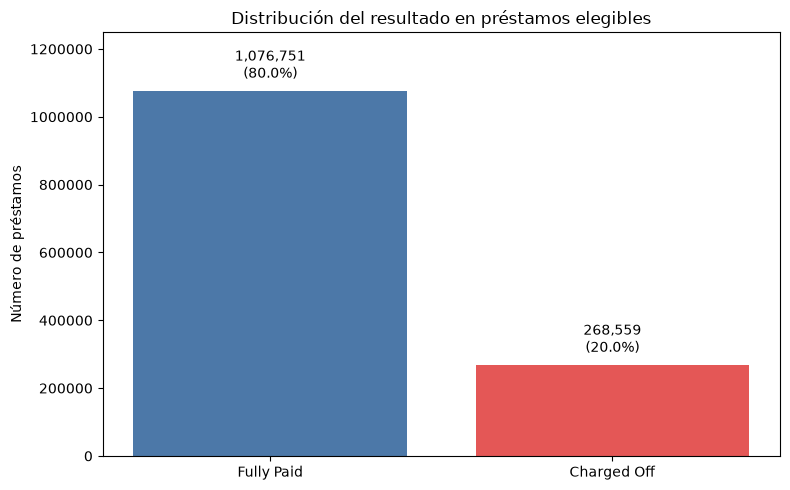

In [23]:
if REPRODUCIR:
    exigir_reproduccion()
    y_total = df.loc[mascara_elegible, "loan_status"].map({"Fully Paid": 0, "Charged Off": 1})
    tabla_objetivo = y_total.value_counts().sort_index().rename(
        index={0: "Fully Paid", 1: "Charged Off"}
    ).to_frame("cantidad")
    tabla_objetivo["porcentaje"] = tabla_objetivo["cantidad"] / tabla_objetivo["cantidad"].sum() * 100
    sesion.mostrar(tabla_objetivo)

    fig, ax = plt.subplots(figsize=(8, 5))
    barras = ax.bar(
        tabla_objetivo.index.astype(str),
        tabla_objetivo["cantidad"],
        color=["#4C78A8", "#E45756"],
    )
    ax.set_title("Distribución del resultado en préstamos elegibles")
    ax.set_ylabel("Número de préstamos")
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.set_ylim(0, tabla_objetivo["cantidad"].max() * 1.16)

    for i, barra in enumerate(barras):
        cantidad = int(tabla_objetivo["cantidad"].iloc[i])
        porcentaje = tabla_objetivo["porcentaje"].iloc[i]
        ax.annotate(
            f"{cantidad:,}\n({porcentaje:.1f}%)",
            xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
        )

    fig.tight_layout()
    sesion.guardar_figura(plt.gcf(), "celda_817045c8")
    plt.show()
else:
    mostrar_resultados_guardados(RAIZ, INDICE_CONSULTA, 12)

### 4.3. Auditoría de faltantes en la primera ventana de entrenamiento

Revisamos los faltantes de las 97 columnas en los préstamos elegibles otorgados hasta 2012, que forman la primera ventana de entrenamiento antes de la validación de 2013. Esta tabla sirve para documentar qué información estaría disponible al iniciar la validación temporal. La selección de predictoras se explica en la sección 4; `loan_status` e `issue_d` se muestran como columnas auxiliares y no cuentan como predictoras.

In [24]:
if REPRODUCIR:
    exigir_reproduccion()
    # La auditoría de cobertura se limita a la primera ventana de entrenamiento: préstamos hasta 2012.
    filas_referencia = int(mascara_hasta_2012.sum())
    faltantes_hasta_2012 = df.loc[mascara_hasta_2012, columnas_revision].isna().sum()
    observados_hasta_2012 = filas_referencia - faltantes_hasta_2012
    porcentaje_hasta_2012 = faltantes_hasta_2012 / filas_referencia * 100

    tabla_faltantes_hasta_2012 = pd.DataFrame({
        "registros_con_dato": observados_hasta_2012,
        "registros_faltantes": faltantes_hasta_2012,
        "porcentaje_faltante": porcentaje_hasta_2012,
        "al_menos_10_pct": np.where(porcentaje_hasta_2012 >= 10, "Sí", "No"),
    })
    tabla_faltantes_hasta_2012 = tabla_faltantes_hasta_2012.loc[
        tabla_faltantes_hasta_2012["registros_faltantes"] > 0
    ].sort_values("porcentaje_faltante", ascending=False)
    tabla_faltantes_hasta_2012.index.name = "variable"

    print(f"Préstamos elegibles hasta 2012 revisados: {filas_referencia:,}")
    print(f"Variables con al menos un faltante: {len(tabla_faltantes_hasta_2012)} de {len(columnas_revision)}")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        sesion.mostrar(mostrar_nombres_espanol(tabla_faltantes_hasta_2012.round(4)))

    # Guardamos la auditoría completa de la primera ventana, incluidas las columnas auxiliares.
    ruta_auditoria_faltantes = SALIDA
    ruta_auditoria_faltantes.mkdir(parents=True, exist_ok=True)
    mostrar_nombres_espanol(tabla_faltantes_hasta_2012.round(4)).to_csv(
        ruta_auditoria_faltantes / "faltantes_97_hasta_2012.csv",
        index_label="variable",
        encoding="utf-8-sig",
    )
else:
    display(pd.read_csv(ORIGEN / "faltantes_97_hasta_2012.csv"))

Préstamos elegibles hasta 2012 revisados: 93,153
Variables con al menos un faltante: 75 de 97


,registros_con_dato,registros_faltantes,porcentaje_faltante,al_menos_10_pct
verificacion_ingresos_conjunta,0,93153,100.0000,Sí
ratio_deuda_ingreso_conjunto,0,93153,100.0000,Sí
ingreso_anual_conjunto,0,93153,100.0000,Sí
creditos_revolventes_abiertos_12m,0,93153,100.0000,Sí
utilizacion_creditos_plazo_pct,0,93153,100.0000,Sí
saldo_total_creditos_plazo,0,93153,100.0000,Sí
meses_desde_credito_plazo_reciente,0,93153,100.0000,Sí
creditos_plazo_abiertos_24m,0,93153,100.0000,Sí
creditos_plazo_abiertos_12m,0,93153,100.0000,Sí
creditos_plazo_activos,0,93153,100.0000,Sí


## 5. Criterio para conservar predictoras

De las **95 predictoras candidatas**, conservamos las que tienen **menos del 10% de faltantes** entre los préstamos elegibles otorgados hasta 2012. Así, la lista fija de variables está disponible desde el primer corte (entrenamiento hasta 2012 y validación en 2013) y puede usarse al comparar todos los modelos. En este análisis quedan **26 predictoras**; `loan_status` e `issue_d` son auxiliares y no forman parte de esa cuenta.

El 10% es un criterio práctico elegido para este proyecto, no un límite universal ni una prueba de que estas sean las variables más predictivas. Las variables descartadas podrían contener información útil, pero su cobertura en la primera ventana es menor. La limitación se documenta para interpretar los resultados.

In [25]:
if REPRODUCIR:
    exigir_reproduccion()
    # Seleccionamos una lista fija usando solo la primera ventana de entrenamiento (hasta 2012).
    # La regla no consulta los años de validación ni el periodo de prueba.
    porcentaje_predictoras_hasta_2012 = porcentaje_hasta_2012.reindex(candidatas)
    columnas_excluidas_10 = porcentaje_predictoras_hasta_2012[
        porcentaje_predictoras_hasta_2012 >= UMBRAL_FALTANTES
    ].index.tolist()
    predictoras_conservadas = [
        c for c in candidatas if c not in columnas_excluidas_10
    ]

    # Tabla de cobertura para las predictoras; las auxiliares no intervienen en la decisión.
    tipos_predictoras = pd.Series(
        {c: clasificar_tipo(c) for c in candidatas}, name="tipo"
    )
    tabla_cobertura_predictoras = pd.DataFrame({
        "observados_hasta_2012": observados_hasta_2012.reindex(candidatas),
        "faltantes_hasta_2012": faltantes_hasta_2012.reindex(candidatas).fillna(
            filas_referencia - observados_hasta_2012.reindex(candidatas)
        ),
        "porcentaje_faltante_hasta_2012": porcentaje_predictoras_hasta_2012,
        "tipo": tipos_predictoras,
        "decision": np.where(
            porcentaje_predictoras_hasta_2012 < UMBRAL_FALTANTES,
            "conservar", "excluir"
        ),
    }).sort_values("porcentaje_faltante_hasta_2012", ascending=False)

    print(f"Préstamos elegibles usados para el criterio: {filas_referencia:,} (hasta 2012)")
    print(f"Predictoras candidatas iniciales: {len(candidatas)}")
    print(f"Excluidas por tener {UMBRAL_FALTANTES}% o más de faltantes: {len(columnas_excluidas_10)}")
    print(f"Conservadas con menos del {UMBRAL_FALTANTES}%: {len(predictoras_conservadas)}")
    print("Predictoras excluidas:")
    sesion.mostrar(mostrar_nombres_espanol(tabla_cobertura_predictoras.loc[columnas_excluidas_10].round(3)))
    print("Predictoras conservadas:")
    tabla_predictoras_conservadas = tabla_cobertura_predictoras.loc[predictoras_conservadas].sort_values(
        "porcentaje_faltante_hasta_2012", ascending=False
    )
    sesion.mostrar(mostrar_nombres_espanol(tabla_predictoras_conservadas.round(3)))

    ruta_salida = SALIDA
    ruta_salida.mkdir(parents=True, exist_ok=True)
    tabla_cobertura_predictoras.to_csv(
        ruta_salida / "cobertura_predictoras_hasta_2012_umbral_10.csv",
        index_label="variable", encoding="utf-8-sig",
    )
    pd.Series(columnas_excluidas_10, name="variable").to_csv(
        ruta_salida / "predictoras_excluidas_10pct_hasta_2012.csv",
        index=False, encoding="utf-8-sig",
    )
    pd.Series(predictoras_conservadas, name="variable").to_csv(
        ruta_salida / "predictoras_conservadas_menos_10pct_hasta_2012.csv",
        index=False, encoding="utf-8-sig",
    )

    # Quitamos del DataFrame solo las predictoras excluidas; se conservan objetivo y fecha.
    df = df.drop(columns=columnas_excluidas_10)
    memoria_reducida = df.memory_usage(index=True, deep=True).sum()
    print("Columnas en tabla tras la selección:", df.shape[1])
    print(f"Memoria profunda de la tabla reducida: {memoria_reducida / 1024**3:.2f} GiB")
else:
    print("No verificable con la evidencia disponible: no se guardó la tabla completa de selección ni sus gráficos. La regla original (<10% hasta 2012; 26 predictoras) permanece documentada.")

Préstamos elegibles usados para el criterio: 93,153 (hasta 2012)
Predictoras candidatas iniciales: 95
Excluidas por tener 10% o más de faltantes: 69
Conservadas con menos del 10%: 26
Predictoras excluidas:


,observados_hasta_2012,faltantes_hasta_2012,porcentaje_faltante_hasta_2012,tipo,decision
meses_desde_ultima_mora,36025,57128,61.327,numérica,excluir
meses_desde_ultimo_registro_publico,4265,88888,95.422,numérica,excluir
meses_desde_ultima_mora_grave,5383,87770,94.221,numérica,excluir
ingreso_anual_conjunto,0,93153,100.000,numérica,excluir
ratio_deuda_ingreso_conjunto,0,93153,100.000,numérica,excluir
...,...,...,...,...,...
creditos_plazo_activos_secundario,0,93153,100.000,numérica,excluir
cuentas_revolventes_secundario,0,93153,100.000,numérica,excluir
castigos_12m_secundario,0,93153,100.000,numérica,excluir
cobranzas_12m_secundario,0,93153,100.000,numérica,excluir


Predictoras conservadas:


,observados_hasta_2012,faltantes_hasta_2012,porcentaje_faltante_hasta_2012,tipo,decision
antiguedad_laboral,90150,3003,3.224,categórica,conservar
quiebras_registradas,92456,697,0.748,numérica,conservar
utilizacion_credito_revolvente_pct,93056,97,0.104,numérica,conservar
cobranzas_no_medicas_12m,93097,56,0.060,numérica,conservar
cuentas_castigadas_12m,93097,56,0.060,numérica,conservar
gravamenes_fiscales,93114,39,0.042,numérica,conservar
plazo_meses,93153,0,0.000,numérica,conservar
tenencia_vivienda,93153,0,0.000,categórica,conservar
ingreso_anual,93153,0,0.000,numérica,conservar
monto_prestamo,93153,0,0.000,numérica,conservar


Columnas en tabla tras la selección: 28
Memoria profunda de la tabla reducida: 0.19 GiB


## 6. Imputación para el análisis descriptivo e indicadores

Para observar las distribuciones completas en los préstamos elegibles de entrenamiento y validación (hasta 2016), hacemos una **copia descriptiva** de las 26 predictoras. En esa copia, rellenamos las variables numéricas con la mediana de entrenamiento + validación y las categóricas con `Sin información`. Esta imputación sirve para las tablas y gráficos de este notebook; **no se reutiliza para entrenar ni evaluar modelos**.

En la validación cruzada, el tratamiento se hará por separado en cada corte: la mediana de cada variable numérica se calcula solo con las filas de entrenamiento de ese corte y se aplica también a su validación. Las categóricas faltantes se completan con `Sin información`. Se comparará el modelo con mediana sola frente a mediana más indicadores de faltante numéricos; cada indicador se crea usando los faltantes observados en el entrenamiento de ese corte. Si una variable estuviera completamente vacía en un entrenamiento, no se calcularía una mediana con datos futuros: se excluiría de ese corte.

In [26]:
if REPRODUCIR:
    exigir_reproduccion()
    columnas_para_desarrollo = predictoras_conservadas + ["loan_status", "issue_d"]
    df_desarrollo = df.loc[mascara_desarrollo, columnas_para_desarrollo].copy()
    y_desarrollo = df_desarrollo["loan_status"].map({"Fully Paid": 0, "Charged Off": 1}).rename("default")
    periodo_desarrollo = pd.Series(
        np.where(df_desarrollo["issue_d"].dt.year < ANIO_CORTE_VALIDACION, "entrenamiento", "validación"),
        index=df_desarrollo.index,
        name="conjunto",
    )

    entrada_features = df_desarrollo[predictoras_conservadas].copy()
    entrada_features["fecha_prestamo"] = df_desarrollo["issue_d"]
    X_desarrollo_original = preparar_matriz(entrada_features).drop(columns="fecha_prestamo")
    # Liberamos el DataFrame cargado: el análisis posterior usa solo desarrollo y las predictoras conservadas.
    del df, df_desarrollo, entrada_features
    for nombre_temporal in ["mascara_elegible", "mascara_hasta_2012", "mascara_desarrollo", "mascara_prueba", "anios", "y_total"]:
        if nombre_temporal in globals():
            del globals()[nombre_temporal]
    gc.collect()
    numericas = X_desarrollo_original.select_dtypes(include="number").columns.tolist()
    categoricas = [c for c in X_desarrollo_original.columns if c not in numericas]

    def nombre_en_matriz(columna):
        if columna in X_desarrollo_original.columns:
            return columna
        derivada = f"meses_desde_{columna}"
        return derivada if derivada in X_desarrollo_original.columns else columna

    # En el análisis descriptivo creamos un indicador para cada numérica con algún faltante.
    # El modelado decidirá con validación si conviene incluirlos.
    columnas_indicadoras = [
        columna for columna in numericas
        if X_desarrollo_original[columna].isna().any()
    ]

    # Para este análisis descriptivo, la mediana se calcula en entrenamiento + validación.
    medianas_descriptivas = pd.Series({c: X_desarrollo_original[c].median() for c in numericas})
    assert medianas_descriptivas.notna().all(), "Hay una variable numérica sin mediana calculable."
    tabla_imputada_descriptiva = X_desarrollo_original.copy()
    # Convertimos e imputamos una columna a la vez para limitar el uso temporal de memoria.
    for columna in numericas:
        tabla_imputada_descriptiva[columna] = (
            tabla_imputada_descriptiva[columna].astype("float64").fillna(medianas_descriptivas[columna])
        )
    for columna in categoricas:
        tabla_imputada_descriptiva[columna] = (
            tabla_imputada_descriptiva[columna].astype(object).where(
                tabla_imputada_descriptiva[columna].notna(), "Sin información"
            )
        )

    tabla_indicadores_faltantes = X_desarrollo_original[columnas_indicadoras].isna().astype("int8")
    tabla_imputada_descriptiva["default"] = y_desarrollo

    print("Filas de entrenamiento + validación; prueba excluida:", f"{len(tabla_imputada_descriptiva):,}")
    sesion.mostrar(periodo_desarrollo.value_counts().rename_axis("conjunto").to_frame("filas"))
    print("Predictoras conservadas:", len(predictoras_conservadas))
    print("Variables numéricas:", len(numericas), "| categóricas:", len(categoricas))
    print("Indicadores numéricos creados:", len(columnas_indicadoras))
    print("Faltantes restantes en la tabla imputada:", int(tabla_imputada_descriptiva.drop(columns="default").isna().sum().sum()))
    print("Tabla con datos imputados:", tabla_imputada_descriptiva.shape)
    print("Tabla de indicadores:", tabla_indicadores_faltantes.shape)
    print("Ejemplo de la tabla imputada:")
    sesion.mostrar(mostrar_nombres_espanol(tabla_imputada_descriptiva.head()))
    print("Ejemplo de la tabla de indicadores:")
    with pd.option_context("display.max_columns", None):
        sesion.mostrar(mostrar_nombres_espanol(tabla_indicadores_faltantes.head()))

    # Guardamos ejemplos pequeños; las tablas completas permanecen disponibles en memoria.
    tabla_imputada_descriptiva.head(1000).to_csv(ruta_salida / "muestra_imputada_descriptiva_1000.csv", encoding="utf-8-sig")
    tabla_indicadores_faltantes.head(1000).to_csv(ruta_salida / "muestra_indicadores_descriptiva_1000.csv", encoding="utf-8-sig")
else:
    mostrar_resultados_guardados(RAIZ, INDICE_CONSULTA, 18)

Filas de entrenamiento + validación; prueba excluida: 1,119,699


,filas
conjunto,
validación,668640
entrenamiento,451059


Predictoras conservadas: 26
Variables numéricas: 20 | categóricas: 6
Indicadores numéricos creados: 7
Faltantes restantes en la tabla imputada: 0
Tabla con datos imputados: (1119699, 27)
Tabla de indicadores: (1119699, 7)
Ejemplo de la tabla imputada:


,monto_prestamo,plazo_meses,antiguedad_laboral,tenencia_vivienda,ingreso_anual,verificacion_ingresos,proposito_prestamo,estado_residencia,ratio_deuda_ingreso,moras_ultimos_2_anios,...,total_lineas_credito,cobranzas_no_medicas_12m,tipo_solicitud,cuentas_en_mora_actual,cuentas_castigadas_12m,monto_en_mora_actual,quiebras_registradas,gravamenes_fiscales,antiguedad_historial_crediticio_meses,incumplimiento
0,3600.0,36.0,10+ years,MORTGAGE,55000.0,Not Verified,debt_consolidation,PA,5.91,0.0,...,13.0,0.0,Individual,0.0,0.0,0.0,0.0,0.0,148.0,0.0
1,24700.0,36.0,10+ years,MORTGAGE,65000.0,Not Verified,small_business,SD,16.06,1.0,...,38.0,0.0,Individual,0.0,0.0,0.0,0.0,0.0,192.0,0.0
2,20000.0,60.0,10+ years,MORTGAGE,63000.0,Not Verified,home_improvement,IL,10.78,0.0,...,18.0,0.0,Joint App,0.0,0.0,0.0,0.0,0.0,184.0,0.0
4,10400.0,60.0,3 years,MORTGAGE,104433.0,Source Verified,major_purchase,PA,25.37,1.0,...,35.0,0.0,Individual,0.0,0.0,0.0,0.0,0.0,210.0,0.0
5,11950.0,36.0,4 years,RENT,34000.0,Source Verified,debt_consolidation,GA,10.20,0.0,...,6.0,0.0,Individual,0.0,0.0,0.0,0.0,0.0,338.0,0.0


Ejemplo de la tabla de indicadores:


,ratio_deuda_ingreso,consultas_credito_6m,utilizacion_credito_revolvente_pct,cobranzas_no_medicas_12m,cuentas_castigadas_12m,quiebras_registradas,gravamenes_fiscales
0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0


## 7. Correlación numérica con el resultado antes y después de imputar

Se compara Spearman entre cada predictora numérica y `default` (0 = Fully Paid; 1 = Charged Off). Antes de imputar, cada correlación usa los préstamos donde ambas variables tienen valor; después, se usa la copia descriptiva completa. Por eso el tamaño de datos que contribuye puede cambiar. Las categóricas no se incluyen en estos mapas; se codificarán en el modelado.

Variables numéricas por grupo: {'A': 5, 'B': 5, 'C': 5, 'D': 5}


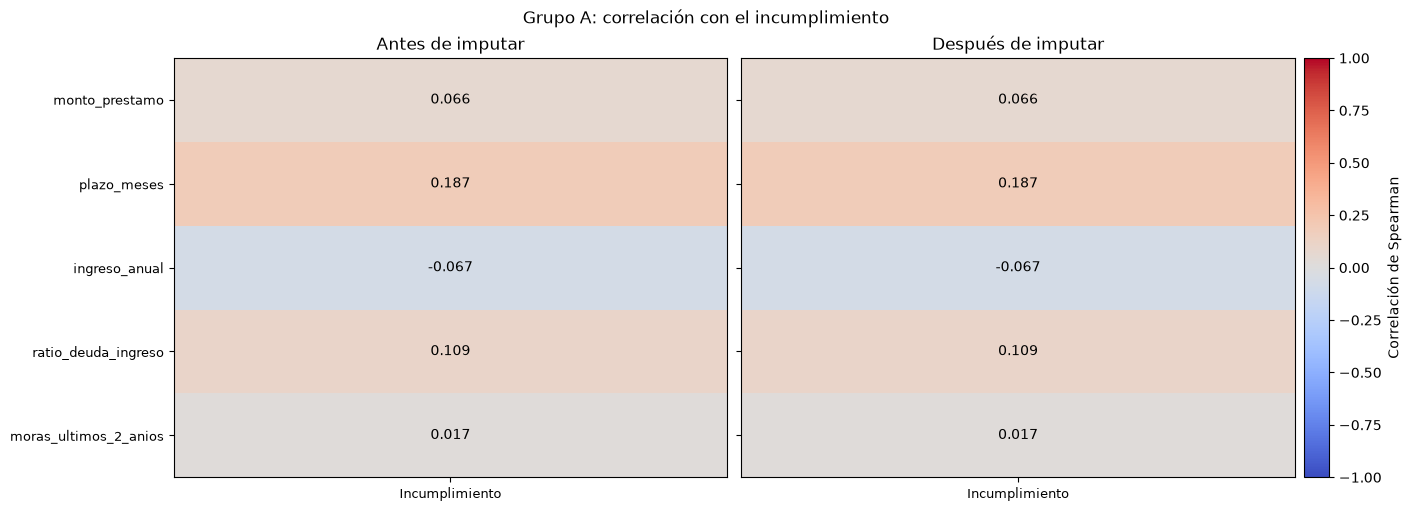

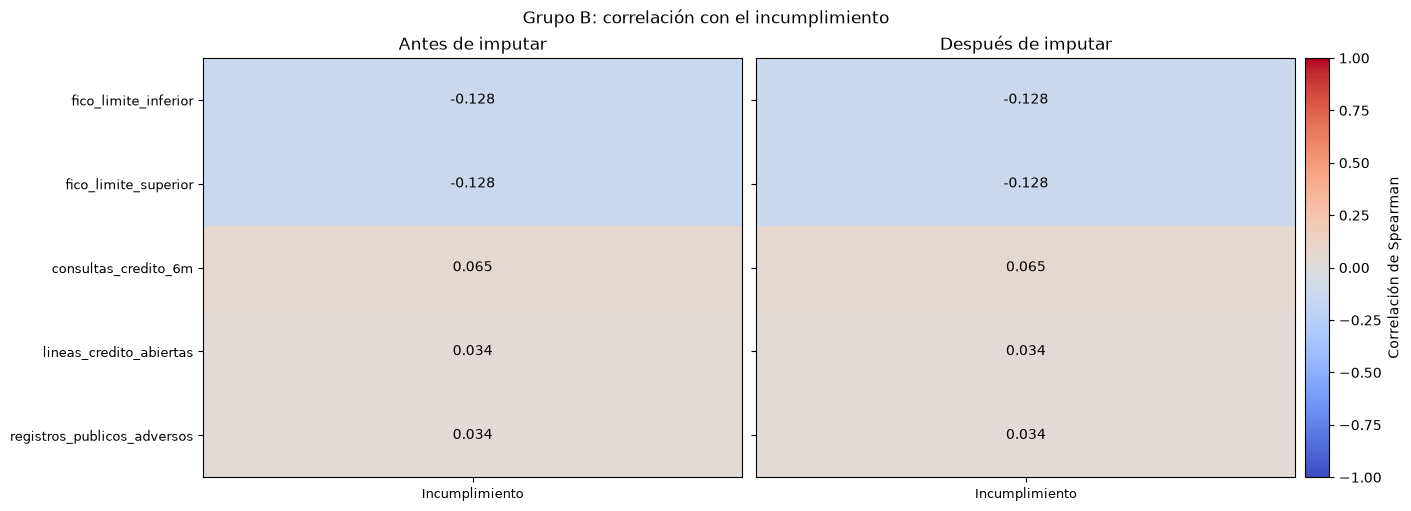

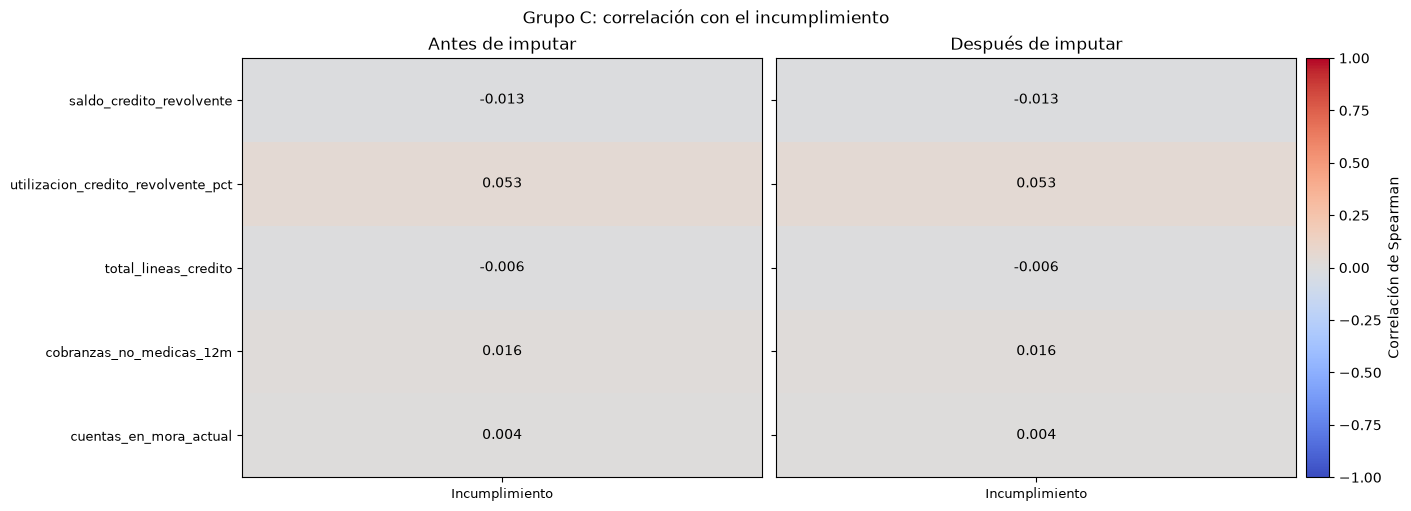

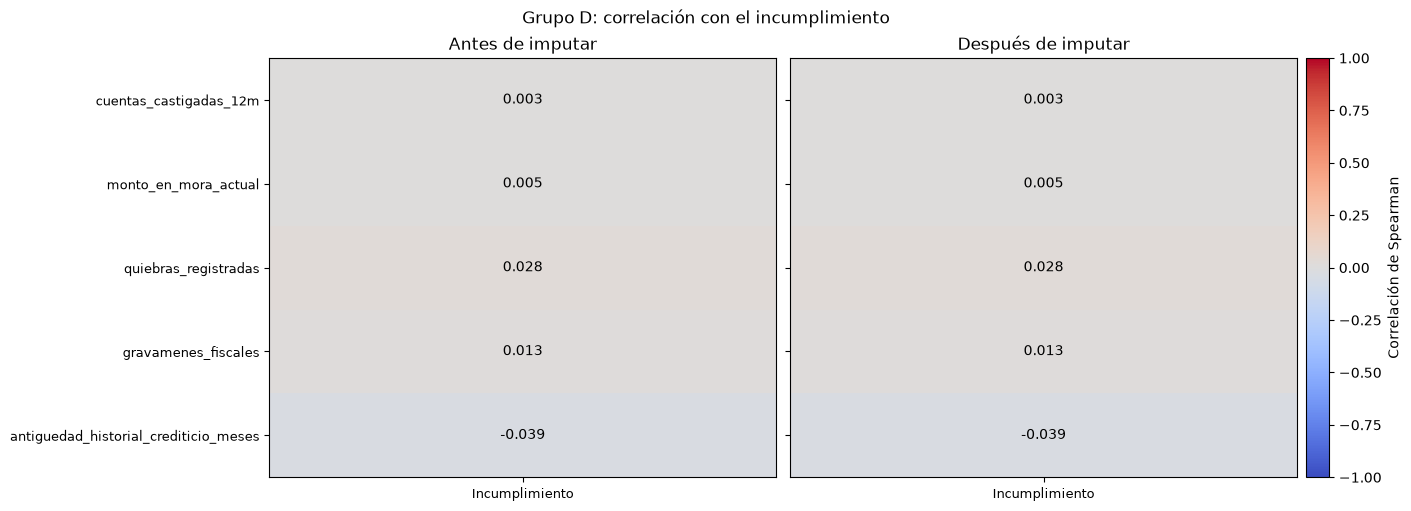

In [27]:
if REPRODUCIR:
    exigir_reproduccion()
    variables_correlacion = numericas
    correlacion_antes = X_desarrollo_original[variables_correlacion].corrwith(
        y_desarrollo, method="spearman"
    ).to_frame("correlacion_default")
    correlacion_despues = tabla_imputada_descriptiva[variables_correlacion].corrwith(
        y_desarrollo, method="spearman"
    ).to_frame("correlacion_default")

    # Repartimos las variables numéricas en cuatro grupos para que los mapas se lean.
    grupo_variables = {
        nombre: columnas.tolist()
        for nombre, columnas in zip(["A", "B", "C", "D"], np.array_split(variables_correlacion, 4))
    }
    print("Variables numéricas por grupo:", {grupo: len(cols) for grupo, cols in grupo_variables.items()})


    def comparar_correlacion_objetivo():
        colores = plt.get_cmap("coolwarm").copy()
        colores.set_bad("lightgray")

        for grupo, variables in grupo_variables.items():
            etiquetas = [nombres_variables.get(str(v), str(v)) for v in variables]
            valores_antes = correlacion_antes.loc[variables, "correlacion_default"].to_numpy()
            valores_despues = correlacion_despues.loc[variables, "correlacion_default"].to_numpy()

            alto = max(5, len(variables) * 0.38)
            fig = plt.figure(figsize=(14, alto), constrained_layout=True)
            rejilla = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.045])
            ax_antes = fig.add_subplot(rejilla[0, 0])
            ax_despues = fig.add_subplot(rejilla[0, 1], sharey=ax_antes)
            ax_color = fig.add_subplot(rejilla[0, 2])

            imagen = None
            for ax, valores, titulo in [
                (ax_antes, valores_antes, "Antes de imputar"),
                (ax_despues, valores_despues, "Después de imputar"),
            ]:
                matriz = np.ma.masked_invalid(valores.astype(float).reshape(-1, 1))
                imagen = ax.imshow(
                    matriz, cmap=colores, vmin=-1, vmax=1, aspect="auto"
                )
                ax.set_title(titulo)
                ax.set_xticks([0], labels=["Incumplimiento"])
                ax.set_yticks(range(len(variables)), labels=etiquetas)
                ax.tick_params(axis="both", labelsize=9)
                for fila, valor in enumerate(valores):
                    texto = f"{valor:.3f}" if pd.notna(valor) else "No calculable"
                    ax.text(0, fila, texto, ha="center", va="center", color="black")

            ax_despues.tick_params(axis="y", labelleft=False)
            fig.colorbar(imagen, cax=ax_color, label="Correlación de Spearman")
            fig.suptitle(f"Grupo {grupo}: correlación con el incumplimiento")
            sesion.guardar_figura(fig, "celda_881227f3")
            sesion.mostrar(fig)
            plt.close(fig)


    comparar_correlacion_objetivo()
else:
    mostrar_resultados_guardados(RAIZ, INDICE_CONSULTA, 20)

## 8. Posibles outliers antes y después de imputar

El IQR se calcula por variable numérica con los valores observados; después se repite en la copia imputada. No eliminamos filas. En la tabla previa, el porcentaje usa solo valores observados; en la posterior, incluye también los valores rellenados. Los boxplots omiten los puntos individuales para evitar saturación visual; la tabla presenta cuántos extremos detecta la regla.

,datos_evaluados_antes,cantidad_extremos_antes,porcentaje_extremos_antes,limite_inferior_antes,limite_superior_antes,datos_evaluados_despues,cantidad_extremos_despues,porcentaje_extremos_despues,limite_inferior_despues,limite_superior_despues
saldo_credito_revolvente,1119699,65062,5.81,-14713.50,40922.50,1119699,65062,5.81,-14713.50,40922.50
consultas_credito_6m,1119698,63061,5.63,-1.50,2.50,1119699,63061,5.63,-1.50,2.50
ingreso_anual,1119699,52359,4.68,-22500.00,157500.00,1119699,52359,4.68,-22500.00,157500.00
lineas_credito_abiertas,1119699,36986,3.30,-1.00,23.00,1119699,36986,3.30,-1.00,23.00
antiguedad_historial_crediticio_meses,1119699,34940,3.12,-24.00,400.00,1119699,34940,3.12,-24.00,400.00
fico_limite_inferior,1119699,34059,3.04,610.00,770.00,1119699,34059,3.04,610.00,770.00
fico_limite_superior,1119699,34059,3.04,614.00,774.00,1119699,34059,3.04,614.00,774.00
total_lineas_credito,1119699,18563,1.66,-8.00,56.00,1119699,18563,1.66,-8.00,56.00
monto_prestamo,1119699,2000,0.18,-10000.00,38000.00,1119699,2000,0.18,-10000.00,38000.00
ratio_deuda_ingreso,1119659,1951,0.17,-6.33,42.23,1119699,1951,0.17,-6.33,42.23


C:\Users\josue\AppData\Local\Temp\ipykernel_36412\3823181282.py:42: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(pd.to_numeric(tabla[columna], errors="coerce").dropna(),
C:\Users\josue\AppData\Local\Temp\ipykernel_36412\3823181282.py:42: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(pd.to_numeric(tabla[columna], errors="coerce").dropna(),
C:\Users\josue\AppData\Local\Temp\ipykernel_36412\3823181282.py:42: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(pd.to_numeric(tabla[columna], errors="coerce").dropna(),
C:\Users\josue\AppData\Local\Temp\ipykernel_36412\3823181282.py:42: MatplotlibDeprecationWarning: vert: bool was de

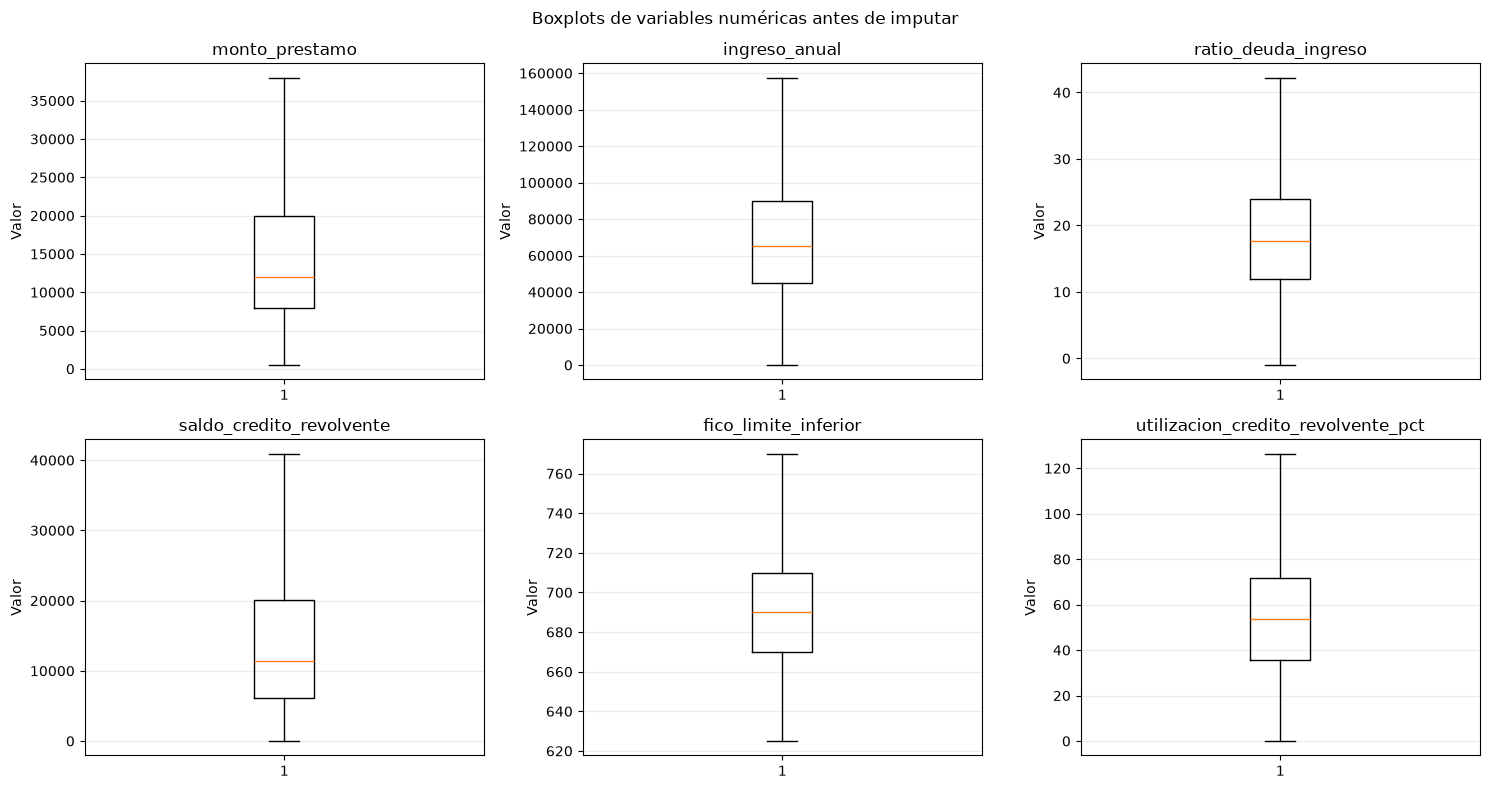

C:\Users\josue\AppData\Local\Temp\ipykernel_36412\3823181282.py:42: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(pd.to_numeric(tabla[columna], errors="coerce").dropna(),
C:\Users\josue\AppData\Local\Temp\ipykernel_36412\3823181282.py:42: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(pd.to_numeric(tabla[columna], errors="coerce").dropna(),
C:\Users\josue\AppData\Local\Temp\ipykernel_36412\3823181282.py:42: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(pd.to_numeric(tabla[columna], errors="coerce").dropna(),
C:\Users\josue\AppData\Local\Temp\ipykernel_36412\3823181282.py:42: MatplotlibDeprecationWarning: vert: bool was de

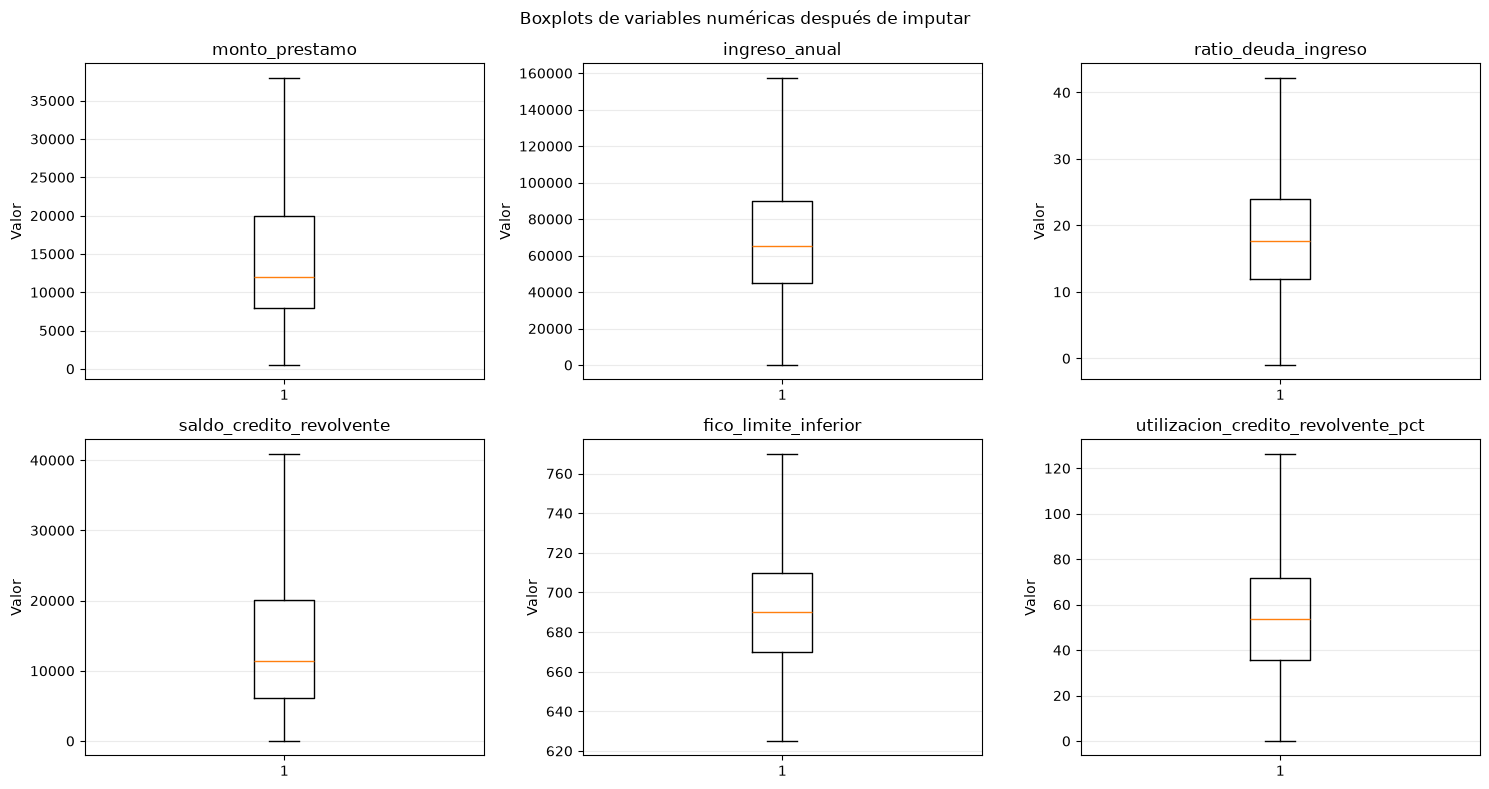

In [28]:
if REPRODUCIR:
    exigir_reproduccion()
    def calcular_outliers_iqr(tabla, momento):
        filas = []
        sin_regla = []
        for columna in numericas:
            valores = pd.to_numeric(tabla[columna], errors="coerce").dropna()
            valores = valores[np.isfinite(valores)]
            if valores.nunique() <= 2 or valores.empty:
                sin_regla.append(columna)
                continue
            q1, q3 = valores.quantile([0.25, 0.75])
            iqr = q3 - q1
            if iqr == 0:
                sin_regla.append(columna)
                continue
            inferior = q1 - 1.5 * iqr
            superior = q3 + 1.5 * iqr
            extremos = (valores < inferior) | (valores > superior)
            filas.append({
                "variable": columna,
                f"datos_evaluados_{momento}": len(valores),
                f"cantidad_extremos_{momento}": int(extremos.sum()),
                f"porcentaje_extremos_{momento}": extremos.mean() * 100,
                f"limite_inferior_{momento}": inferior,
                f"limite_superior_{momento}": superior,
            })
        return pd.DataFrame(filas).set_index("variable"), sin_regla

    tabla_iqr_antes, sin_regla_antes = calcular_outliers_iqr(X_desarrollo_original, "antes")
    tabla_iqr_despues, sin_regla_despues = calcular_outliers_iqr(tabla_imputada_descriptiva.drop(columns="default"), "despues")
    tabla_comparacion_iqr = tabla_iqr_antes.join(tabla_iqr_despues, how="outer")
    tabla_comparacion_iqr = tabla_comparacion_iqr.sort_values("porcentaje_extremos_antes", ascending=False)
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        sesion.mostrar(mostrar_nombres_espanol(tabla_comparacion_iqr.round(2)))

    variables_boxplot = [c for c in ["loan_amnt", "annual_inc", "dti", "revol_bal", "fico_range_low", "revol_util"] if c in numericas]
    for momento, tabla in [("antes de imputar", X_desarrollo_original),
                           ("después de imputar", tabla_imputada_descriptiva.drop(columns="default"))]:
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        for ax, columna in zip(axes.flat, variables_boxplot):
            ax.boxplot(pd.to_numeric(tabla[columna], errors="coerce").dropna(),
                       vert=True, showfliers=False)
            ax.set_title(nombres_variables.get(columna, columna))
            ax.set_ylabel("Valor")
            ax.grid(axis="y", alpha=0.25)
        for ax in axes.flat[len(variables_boxplot):]:
            ax.set_visible(False)
        fig.suptitle(f"Boxplots de variables numéricas {momento}")
        fig.tight_layout()
        sesion.guardar_figura(fig, "celda_fe4af809")
        sesion.mostrar(fig)
        plt.close(fig)
else:
    mostrar_resultados_guardados(RAIZ, INDICE_CONSULTA, 22)

## 9. Conclusiones y limitaciones

- La selección parte de 95 predictoras candidatas y conserva 26 con menos del 10% de faltantes en la primera ventana de entrenamiento, hasta 2012. La selección es fija para comparar los modelos y no consulta los años de validación ni el periodo de prueba.
- El umbral del 10% es una decisión práctica del proyecto, no un valor universal. Podrían quedar fuera variables útiles con menor cobertura; por eso no afirmamos que las 26 sean el conjunto óptimo.
- La imputación de este notebook es solo descriptiva. En cada corte de modelado, las medianas se calcularán únicamente con el entrenamiento y se aplicarán a la validación. Las categorías vacías se marcarán como `Sin información`; se comparará mediana sola con mediana más indicadores numéricos.
- Spearman y los boxplots se comparan antes y después de la imputación descriptiva. La regla IQR señala valores extremos, pero no demuestra que sean errores; no se eliminan observaciones.
- Solo se observan préstamos aceptados con resultado final, no cómo habrían pagado los rechazados. También falta confirmar el tiempo de seguimiento de las cohortes recientes.

## 10. Referencias

Madley-Dowd, P., Hughes, R. A., Tilling, K., & Heron, J. (2019). The proportion of missing data should not be used to guide decisions on multiple imputation. *Journal of Clinical Epidemiology, 110*, 63–73. https://doi.org/10.1016/j.jclinepi.2019.02.016

Perez-Lebel, A., Varoquaux, G., Le Morvan, M., Josse, J., & Poline, J.-B. (2022). Benchmarking missing-values approaches for predictive models on health databases. *GigaScience, 11*, giac013. https://doi.org/10.1093/gigascience/giac013

### Reproducir la auditoría del anexo

Se utiliza el programa histórico de rangos y carga directa/bloques. El benchmark histórico de fases de entrenamiento es una referencia separada, no se vuelve a entrenar en el EDA.

In [29]:
if REPRODUCIR:
    exigir_reproduccion()
    from src.auditoria_memoria import ejecutar as auditar_memoria
    auditar_memoria(RAIZ, SALIDA, ruta_datos=RUTA_DATOS)
else:
    print("Anexo en consulta: no se vuelve a leer el CSV.")

Archivo: accepted_2007_to_2018Q4.csv.gz
Columnas: 151
Versiones: 3.12.10 pandas 3.0.3 numpy 2.4.6
Archivo completo: 2,260,701 filas, 151 columnas y 46 bloques.
No se excluyó ningún estado de préstamo.


,observados,faltantes,minimo,maximo,todos_enteros,no_finitos,tipo_original,tipo_propuesto
loan_amnt,2260668,33,500.0,40000.0,True,0,float64,Int32
funded_amnt,2260668,33,500.0,40000.0,True,0,float64,Int32
funded_amnt_inv,2260668,33,0.0,40000.0,False,0,float64,float64
int_rate,2260668,33,5.31,30.99,False,0,float64,float64
installment,2260668,33,4.93,1719.83,False,0,float64,float64
annual_inc,2260664,37,0.0,110000000.0,False,0,float64,float64
dti,2258957,1744,-1.0,999.0,False,0,float64,float64
delinq_2yrs,2260639,62,0.0,58.0,True,0,float64,Int8
fico_range_low,2260668,33,610.0,845.0,True,0,float64,Int16
fico_range_high,2260668,33,614.0,850.0,True,0,float64,Int16


Verificadas 2,260,701 filas y 151 columnas.
Cambios de valores en la opción conservadora: 0
Cambios de faltantes en la opción conservadora: 0


,observados,valores_cambiados,error_absoluto_max,error_relativo_max,nuevos_infinitos,nuevos_ceros,porcentaje_cambiado
annual_inc,2260664,16099,0.04,5.7207505e-08,0,0,0.7121359
annual_inc_joint,120710,1447,0.015,5.7199372e-08,0,0,1.1987408
total_pymnt,2260668,2204488,0.0019531126,5.9544508e-08,0,0,97.514894
funded_amnt_inv,2260668,8449,0.001914017,5.7518127e-08,0,0,0.37373909
total_rec_prncp,2260668,1128801,0.001875,5.7220319e-08,0,0,49.932188
out_prncp,2260668,870382,0.001875,5.7218853e-08,0,0,38.501098
total_pymnt_inv,2260668,2167159,0.001875,5.7220319e-08,0,0,95.863656
out_prncp_inv,2260668,870515,0.001875,5.7218853e-08,0,0,38.506981
last_pymnt_amnt,2260668,2140451,0.001875,5.7586805e-08,0,0,94.682236
hardship_payoff_balance_amount,10917,10481,0.001875,5.7098344e-08,0,0,96.006229


Valores alterados por float32: 23412405
Infinitos nuevos: 0
Ceros nuevos: 0


,memoria_acumulada_MiB,reduccion_pct
Lectura actual,6887.47,0.00
Conservadora (exacta),2360.93,65.72
Experimental (+ float32),2119.46,69.23


... (3 outputs left out)

Filas auditadas: 2,260,701; columnas: 151.
Reducción conservadora acumulada: 65.72%.
La opción conservadora preservó exactamente valores y faltantes respecto de la lectura actual.
float32 NO conserva exactamente todos los valores: mantener float64 en esas columnas si se exige igualdad exacta.
Columnas leídas en ambos métodos: 97
Filas fuente que leerá cada ejecución: 2,260,701
Tamaño de bloque para el segundo método: 50,000 filas

Midiendo directa, repetición 1...
directa: carga y filtro en 47.53 s

Midiendo bloques, repetición 1...
bloques: carga y filtro en 52.53 s

Midiendo bloques, repetición 2...
bloques: carga y filtro en 48.85 s

Midiendo directa, repetición 2...
directa: carga y filtro en 46.44 s

Midiendo directa, repetición 3...
directa: carga y filtro en 51.04 s

Midiendo bloques, repetición 3...
bloques: carga y filtro en 42.35 s

Mediciones terminadas.
Las dos formas leyeron y conservaron los mismos datos.


,método,repetición,filas_leídas,préstamos_elegibles,tiempo_segundos
0,directa,1,2260701,1345310,47.53
1,bloques,1,2260701,1345310,52.53
2,bloques,2,2260701,1345310,48.85
3,directa,2,2260701,1345310,46.44
4,directa,3,2260701,1345310,51.04
5,bloques,3,2260701,1345310,42.35


,repeticiones,mediana_segundos,promedio_segundos,mínimo_segundos,máximo_segundos
método,,,,,
directa,3,47.53,48.34,46.44,51.04
bloques,3,48.85,47.91,42.35,52.53


Método más rápido por mediana: directa.
Su mediana fue 2.7% menor que la del otro método.


## Anexo. Auditoría de memoria y velocidad de carga

Este anexo incorpora la comparación de `04_exploracion_completa.ipynb`. Lee los registros ya guardados; no vuelve a cargar el CSV ni repite el benchmark. La comparación de lectura completa frente a bloques tuvo tres repeticiones por método y verificó la misma huella de datos.

In [30]:

RAIZ = raiz_proyecto()
if not (RAIZ / "outputs").exists():
    RAIZ = RAIZ.parent

carpeta_carga = SALIDA / "comparacion_carga" if REPRODUCIR else RAIZ / "outputs/comparacion_carga"
registros = []
for metodo in ["directa", "bloques"]:
    for repeticion in [1, 2, 3]:
        archivo_resultado = carpeta_carga / f"{metodo}_{repeticion}.json"
        registros.append(json.loads(archivo_resultado.read_text(encoding="utf-8")))

tiempos = pd.DataFrame(registros)
resumen_carga = tiempos.groupby("metodo").agg(
    repeticiones=("segundos_carga", "count"),
    segundos_promedio=("segundos_carga", "mean"),
    segundos_desviacion=("segundos_carga", "std"),
    filas_fuente=("filas_fuente", "first"),
    prestamos_elegibles=("filas_elegibles", "first"),
    huellas_distintas=("huella_datos", "nunique"),
).round(2)
display(resumen_carga)

if REPRODUCIR:
    print("El anexo de carga usa la auditoría recién reproducida. Las fases históricas de entrenamiento no se repiten en este EDA.")
else:
    mostrar_resultados_guardados(RAIZ, INDICE_CONSULTA, 26)

,repeticiones,segundos_promedio,segundos_desviacion,filas_fuente,prestamos_elegibles,huellas_distintas
metodo,,,,,,
bloques,3,47.91,5.15,2260701,1345310,1
directa,3,48.34,2.40,2260701,1345310,1


El anexo de carga usa la auditoría recién reproducida. Las fases históricas de entrenamiento no se repiten en este EDA.


**Lectura:** los tiempos son mediciones de esta computadora y ejecución, no una garantía universal. El benchmark conserva los resultados registrados y ayuda a justificar la elección de lectura; no sustituye las mediciones de memoria y entrenamiento documentadas en la auditoría original. El código de auditoría está en `src/auditoria_memoria.py`; las mediciones que usa este anexo permanecen en `outputs/`.

In [31]:
if REPRODUCIR:
    exigir_reproduccion()
    tabla_cobertura_predictoras.to_csv(SALIDA / "cobertura_predictoras_hasta_2012_umbral_10.csv", index_label="variable")
    correlacion_antes.to_csv(SALIDA / "correlacion_antes.csv", index_label="variable")
    correlacion_despues.to_csv(SALIDA / "correlacion_despues.csv", index_label="variable")
    tabla_comparacion_iqr.to_csv(SALIDA / "comparacion_iqr.csv", index_label="variable")
else:
    print("No se exportan tablas en consulta.")

## Verificación de reproducibilidad

La comparación usa los valores guardados sin redondearlos: tolerancia absoluta `1e-8` y relativa `1e-6` para números reales, e igualdad exacta para enteros y categorías. En la tabla de faltantes, la evidencia anterior incluía las 97 variables y nombres originales; para compararla se filtran las variables con al menos un faltante, se traducen sus nombres y se adapta el esquema a la tabla actual. En ese único porcentaje redondeado se permite una diferencia máxima de `0.00005` puntos porcentuales; los conteos y la decisión del umbral deben coincidir exactamente.

Las filas CSV se alinean por sus claves metodológicas cuando existen y se comprueba que no estén duplicadas. Los tiempos no tienen que coincidir. Se contrastan tamaños, decisiones y configuraciones disponibles, además de las métricas; una AUC igual no prueba que se hayan usado las mismas observaciones. Sin evidencia de identidad, se indica **No verificable con la evidencia disponible**. Las figuras se presentan para inspección visual; no se afirma identidad de píxeles.

**Coincide** y **Difiere** requieren una reproducción ejecutada. **No verificado** significa que solo se consultaron resultados. **No verificable** señala una referencia ausente o insuficiente. La consulta nunca se presenta como una reproducción exitosa.

In [32]:
from src.reproduccion_notebooks import comparar_archivos, comparar_tablas


def comparar_faltantes_compatibles(original, reproducido):
    if original.name != "faltantes_97_hasta_2012.csv":
        return comparar_archivos(original, reproducido)

    historica = pd.read_csv(original)
    actual = pd.read_csv(reproducido)
    historica = historica.loc[historica["faltantes_hasta_2012"] > 0].copy()
    historica["variable"] = historica["variable"].map(
        lambda nombre: nombres_variables.get(str(nombre), str(nombre))
    )
    historica = historica.rename(columns={
        "observados_hasta_2012": "registros_con_dato",
        "faltantes_hasta_2012": "registros_faltantes",
        "porcentaje_faltante_hasta_2012": "porcentaje_faltante",
    })
    historica["al_menos_10_pct"] = np.where(
        historica["porcentaje_faltante"] >= 10, "Sí", "No"
    )
    columnas_actuales = actual.columns.tolist()
    historica = historica[columnas_actuales]

    return comparar_tablas(
        historica,
        actual,
        elemento="faltantes_97_hasta_2012.csv (comparación normalizada)",
        claves=["variable"],
        atol=5e-5,
        rtol=0,
    )


verificacion = sesion.finalizar(
    PARES_VERIFICACION,
    configuracion={
        "etapa": "04_exploracion",
        "semilla": 42,
        "filtro": "menos de 10% hasta 2012",
        "imputacion": "descriptiva sobre desarrollo hasta 2016",
    },
    datos=archivo if REPRODUCIR else None,
    comparador=comparar_faltantes_compatibles,
)
display(verificacion)
print("Resumen de verificación:", verificacion["Estado"].value_counts().to_dict())

,Elemento,Original,Reproducido,Diferencia,Estado
0,faltantes_97_hasta_2012.csv/filas,97,75,-22,Difiere
1,faltantes_97_hasta_2012.csv/columnas,"[""variable"", ""observados_hasta_2012"", ""faltant...","[""variable"", ""registros_con_dato"", ""registros_...",None,Difiere
2,faltantes_97_hasta_2012.csv/claves,"[""[\""acc_now_delinq\""]"", ""[\""acc_open_past_24m...","[""[\""antiguedad_laboral\""]"", ""[\""castigos_12m_...",Diferencias en observaciones de la tabla,Difiere
3,bloques_1.json/filas_elegibles,1345310,1345310,0.0,Coincide
4,bloques_1.json/filas_fuente,2260701,2260701,0.0,Coincide
5,bloques_1.json/huella_datos,"""5208c899c5e7ad7bd8c8ae8569c73808c69df9fc2aa44...","""5208c899c5e7ad7bd8c8ae8569c73808c69df9fc2aa44...",NaN,Coincide
6,bloques_1.json/metodo,"""bloques""","""bloques""",NaN,Coincide
7,bloques_1.json/repeticion,1,1,0.0,Coincide
8,bloques_2.json/filas_elegibles,1345310,1345310,0.0,Coincide
9,bloques_2.json/filas_fuente,2260701,2260701,0.0,Coincide


Resumen de verificación: {'Coincide': 42, 'No verificable': 9, 'Difiere': 3}
